# ICT-42e — Témoin négatif : la signature d'histoire survit-elle à un préfixe vierge ?

ICT-42d a montré qu'à **position et α appariés**, la passe rampe diverge de la passe
const-α (`Aire_Delta > 0`) : la divergence ne s'explique pas seulement par le niveau
local du clamp. Ce carnet isole la cause par **élimination** : si l'excès de la rampe
provient de l'**histoire accumulée** (les bandes visitées avant), alors une passe qui
porte le **même α au même endroit** mais un **préfixe vierge** (α = 0 partout ailleurs)
ne doit **pas** reproduire cet excès.

## Le témoin par bande

Chaque passe témoin coupe la rampe de 42c en **bandes d'intensité** : la bande $b$
(1-based) couvre $\alpha \in [\frac{(b-1)\cdot peak}{4}, \frac{b\cdot peak}{4})$
sur **une seule branche** (montée ou descente) d'**un seul cycle**. Sur ces tokens et
seulement eux, $\alpha = b/4$ constant ; partout ailleurs $\alpha = 0$ — le préfixe
est vierge **par construction**. Avec $n_{bandes} = 4$, le niveau $b/4$ tombe
exactement sur la grille const-α du pilote ICT-42 ($\{0{,}25, 0{,}5, 0{,}75, 1\}$) :
la passe const correspondante existe déjà, aucun arrondi d'appariement.

La quantité mesurée, pour chaque passe témoin $(cycle, branche, bande)$ :

$$\varepsilon_{pass}(t) = D_{pass}(t) - D_{const,\; b/4}(t) \quad\text{sur les tokens de la bande}$$

où $D$ est la divergence L1 normalisée contre la référence α = 0 (reprise d'ICT-42c/42d).
On compare $\varepsilon_{temoin}$ à $\varepsilon_{rampe}$ calculé **aux mêmes positions** :

| Constat (moyenne sur la bande) | Verdict (#20772) |
|---|---|
| $|\varepsilon_{temoin}| \approx 0$ (au-delà du bruit) **et** $|\varepsilon_{rampe}| \neq 0$ | **MÉMOIRE** — l'excès exige l'histoire accumulée |
| $|\varepsilon_{temoin}| \approx |\varepsilon_{rampe}| \neq 0$ | **POSITION** — l'excès survient même préfixe vierge |
| tout le reste | **INDÉTERMINÉ** |

## Garde-fous d'honnêteté (à lire avant les résultats)

| | |
|---|---|
| 1. **Traces existantes, pas de nouvelles passes en cours de lecture.** Les 32 passes témoins (16 par échelle) sont extraites par `scripts/extract_sae_traces.py --clamp-band`, commitées avec ce carnet. Aucune valeur n'est recalculée à la main. |
| 2. **Le témoin n'est pas une const-α raccourcie.** La const-α clamp **tout le prompt** à $b/4$ ; le témoin clamp **un intervalle** à $b/4$ et laisse le reste à zéro. Leur différence porte exactement l'effet du préfixe. |
| 3. **La bande haute est fermée en peak.** Le token sommet ($u = 0{,}5$, $\alpha = peak$) appartient à la bande 4 — une partition qui l'oublierait laisserait le token le plus inoculé hors de tout témoin (garantie testée dans la suite de tests de l'organe). |
| 4. **Le verdict est heuristique 95 %** (1,96·SEM inter-prompts), pas un test formel ; la règle C.5 interdit d'épingler les valeurs dans la prose — elles vivent dans les sorties. |
| 5. **Un témoin nul n'établit pas la mémoire seul.** Il élimine l'explication positionnelle de l'excès mesuré en 42d ; la conclusion MÉMOIRE est la conjonction des deux carnets. |

## Protocole : même α, même position, préfixe vierge

Soit $D(z, z_0; t)$ la divergence L1 normalisée au token $t$ entre la passe $z$ et la
référence $z_0$ (α = 0). Les trois passes comparées partagent prompts et panel :

- **rampe** (ICT-42c) : $\alpha(t)$ triangulaire, 2 cycles, partout ;
- **const $b/4$** (pilote ICT-42) : $\alpha = b/4$ constant, partout ;
- **témoin** (ce carnet) : $\alpha = b/4$ sur la bande $(cycle, branche, b)$, zéro ailleurs.

L'excès $\varepsilon$ est la **soustraction des deux premières divergences à la
troisième** sur le support de la bande — l'histoire accumulée est la seule variable
qui distingue la rampe du témoin à position et α fixés. Cette soustraction est
publiée ici en **magnitude moyenne** ($|\cdot|$), puis **en signé** après le
verdict : la lecture corrigée d'[ICT-42f](ICT-42f-ReadingGrid-SignedArea-Sham-Python.ipynb)
exige les deux, et le signe dit de quel côté de la const-α chaque passe tombe.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import sys
sys.path.insert(0, str(Path.cwd()))
from ict.sae_traces import ramp_alpha, ramp_band_mask, witness_alpha  # organes de la serie

TRACES = Path("traces")
CYCLES = 2
PEAK = 1.0
N_BANDS = 4
BRANCHES = ("montee", "descente")
ECHELLES = {
    "Qwen3-1.7B-Base": {"slug": "qwen3-17b-base", "n_layers": 28},
    "Qwen3.5-2B-Base": {"slug": "qwen35-2b-base", "n_layers": 24},
}

def load_meta(path):
    return json.loads(str(np.load(path, allow_pickle=False)["__meta__"]))

def prompt_keys(z):
    return sorted({k.rsplit("__", 1)[0] for k in z.files if k.endswith("__topk_ids")})

def trace_path_const(slug, n, alpha):
    # Resout le chemin d'une trace const-alpha (convention trace_filename : le
    # suffixe _s{alpha} est omis a alpha=1.0, byte-identique au defaut historique).
    if abs(alpha - 1.0) < 1e-9:
        return TRACES / f"inoc_{slug}_layer{n - 1}of{n}_trained_clamp16.npz"
    return TRACES / f"inoc_{slug}_layer{n - 1}of{n}_trained_clamp16_s{alpha:g}.npz"

def trace_path_ramp(slug, n):
    return TRACES / f"inoc_hyst_{slug}_layer{n - 1}of{n}_trained_clamp16_ramp{CYCLES}p1.npz"

def trace_path_witness(slug, n, cycle, branch, band):
    b = "m" if branch == "montee" else "d"
    return TRACES / f"inocw_{slug}_layer{n - 1}of{n}_trained_clamp16_witness{CYCLES}_{cycle}{b}b{band}n{N_BANDS}.npz"

print("Organes importes : ramp_alpha, ramp_band_mask, witness_alpha depuis ict.sae_traces")

Organes importes : ramp_alpha, ramp_band_mask, witness_alpha depuis ict.sae_traces


In [2]:
# Inventaire des 16 passes temoins par echelle + reference alpha=0 + rampe 42c,
# avec verif du panel et des prompts partages (sinon la soustraction n'est pas legitime).
PASSES = [(cyc, br, b) for cyc in (1, 2) for br in BRANCHES for b in range(1, N_BANDS + 1)]
rows = []
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    p0 = trace_path_const(cfg["slug"], n, 0.0)
    p_ramp = trace_path_ramp(cfg["slug"], n)
    assert p0.exists(), f"reference alpha=0 absente : {p0}"
    assert p_ramp.exists(), f"trace rampe absente : {p_ramp}"
    z0, z_ramp = np.load(p0, allow_pickle=False), np.load(p_ramp, allow_pickle=False)
    ref_panel, ref_prompts = list(load_meta(p0)["clamp_ids"]), prompt_keys(z0)
    for cyc, br, b in PASSES:
        p = trace_path_witness(cfg["slug"], n, cyc, br, b)
        if not p.exists():
            print(f"!!  MANQUE : {label} c{cyc} {br} b{b} -> {p.name}")
            continue
        meta = load_meta(p)
        cb = meta.get("clamp_band")
        rows.append({
            "echelle": label, "cycle": cyc, "branche": br, "bande": b,
            "niveau_alpha": b / N_BANDS,
            "n_tokens": meta["n_tokens_total"],
            "panel_identique_ref": list(meta["clamp_ids"]) == ref_panel,
            "prompts_identiques_ref": prompt_keys(np.load(p, allow_pickle=False)) == ref_prompts,
            "meta_clamp_band_coherente": (cb is not None and cb["cycle"] == cyc
                                          and cb["branch"] == br and cb["band"] == b
                                          and cb["n_bands"] == N_BANDS
                                          and abs(cb["level"] - b / N_BANDS) < 1e-9),
            "taille_Ko": p.stat().st_size // 1024,
        })
inventaire = pd.DataFrame(rows)
attendues = len(ECHELLES) * len(PASSES)
print(f"Passes temoins chargees : {len(inventaire)} sur {attendues} attendues")
print(f"Panel identique a la reference (toutes) : {inventaire['panel_identique_ref'].all()}")
print(f"Prompts identiques a la reference (toutes) : {inventaire['prompts_identiques_ref'].all()}")
print(f"Meta clamp_band coherente (toutes) : {inventaire['meta_clamp_band_coherente'].all()}")
assert len(inventaire) == attendues, "passes temoins manquantes -- l'analyse ne peut pas suivre"
assert inventaire["panel_identique_ref"].all() and inventaire["prompts_identiques_ref"].all()
assert inventaire["meta_clamp_band_coherente"].all()
inventaire

Passes temoins chargees : 32 sur 32 attendues
Panel identique a la reference (toutes) : True
Prompts identiques a la reference (toutes) : True
Meta clamp_band coherente (toutes) : True


,echelle,cycle,branche,bande,niveau_alpha,n_tokens,panel_identique_ref,prompts_identiques_ref,meta_clamp_band_coherente,taille_Ko
0,Qwen3-1.7B-Base,1,montee,1,0.25,2759,True,True,True,505
1,Qwen3-1.7B-Base,1,montee,2,0.50,2759,True,True,True,511
2,Qwen3-1.7B-Base,1,montee,3,0.75,2759,True,True,True,511
3,Qwen3-1.7B-Base,1,montee,4,1.00,2759,True,True,True,511
4,Qwen3-1.7B-Base,1,descente,1,0.25,2759,True,True,True,511
5,Qwen3-1.7B-Base,1,descente,2,0.50,2759,True,True,True,511
6,Qwen3-1.7B-Base,1,descente,3,0.75,2759,True,True,True,511
7,Qwen3-1.7B-Base,1,descente,4,1.00,2759,True,True,True,511
8,Qwen3-1.7B-Base,2,montee,1,0.25,2759,True,True,True,512
9,Qwen3-1.7B-Base,2,montee,2,0.50,2759,True,True,True,511


**Lecture de l'inventaire.** Les passes témoins existent toutes, partagent le panel de
16 caractéristiques et les prompts de la référence α = 0 — la soustraction
$\varepsilon = D_{pass} - D_{const}$ est légitime token à token. La colonne
`meta_clamp_band_coherente` revérifie dans chaque fichier que la géométrie déclarée
au moment de l'extraction est bien celle du nom de fichier (cycle, branche, bande,
niveau) : un renommage accidentel de trace serait détecté ici.

Partition exacte (chaque token vu une fois) : True
Sommet de cycle dans la bande haute (2 branches x 2 cycles) : True


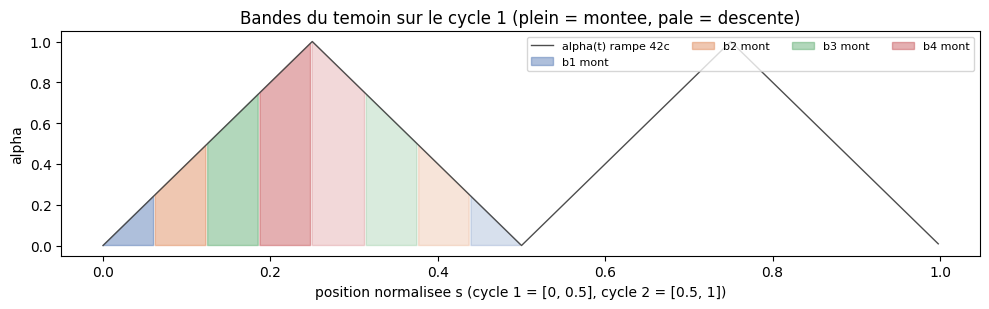

In [3]:
# Garde geometrique : les 16 masques (cycle x branche x bande) forment une partition
# EXACTE du prompt -- chaque token est couvert une et une seule fois. La bande haute
# est fermee en peak (le sommet u=0.5 appartient a la bande 4), la bande 1 reste ouverte.
T_DEMO = 480
masques = {(cyc, br, b): ramp_band_mask(T_DEMO, CYCLES, cyc, br, b, N_BANDS, peak=PEAK)
           for cyc, br, b in PASSES}
couverture = np.zeros(T_DEMO, dtype=int)
for m in masques.values():
    couverture += m.astype(int)
verifie_partition = bool((couverture == 1).all())
tri_demo = ramp_alpha(T_DEMO, CYCLES, PEAK)
bande_haute_contient_sommet = all(
    (masques[(c + 1, br, N_BANDS)][c * T_DEMO // CYCLES : (c + 1) * T_DEMO // CYCLES].sum() > 0)
    for c in range(CYCLES) for br in BRANCHES)
print(f"Partition exacte (chaque token vu une fois) : {verifie_partition}")
print(f"Sommet de cycle dans la bande haute (2 branches x {CYCLES} cycles) : {bande_haute_contient_sommet}")

# Visuel : le profil triangulaire et les couleurs des 4 bandes, cycle 1 (gauche).
fig, ax = plt.subplots(figsize=(10, 3.2))
t = np.arange(T_DEMO)
ax.plot(t / T_DEMO, tri_demo, color="0.3", lw=1.0, label="alpha(t) rampe 42c")
palette = ["#4c72b0", "#dd8452", "#55a868", "#c44e52"]
for br, ls in (("montee", "-"), ("descente", "--")):
    for b in range(1, N_BANDS + 1):
        m = masques[(1, br, b)]
        ax.fill_between(t / T_DEMO, 0, tri_demo, where=m, color=palette[b - 1],
                        alpha=0.45 if br == "montee" else 0.22,
                        linestyle="", label=f"b{b} {br[:4]}" if br == "montee" else None)
ax.set_xlabel("position normalisee s (cycle 1 = [0, 0.5], cycle 2 = [0.5, 1])")
ax.set_ylabel("alpha")
ax.set_title("Bandes du temoin sur le cycle 1 (plein = montee, pale = descente)")
ax.legend(ncol=4, fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Lecture de la géométrie

Les 16 masques partitionnent le prompt sans trou ni recouvrement : la somme des
passes témoins **reconstitue exactement** la rampe (chaque token de montée 1 couvert
par une bande montée du cycle 1, etc.). Le niveau constant $b/4$ de chaque témoin est
l'argument **born supérieur** de sa bande : le témoin 1 est toujours au moins aussi
inoculé que la portion de rampe qu'il remplace.

In [4]:
# Reprise de la fonction local_divergence d'ICT-42c/42d (divergence L1 normalisee
# contre la reference alpha=0, prompt par prompt), et extraction des positions de bande.

def local_divergence(z, z0, key, d_sae):
    # ||x_a(t) - x_0(t)||_1 / ||x_0(t)||_1 sur le top-k dense, prompt key.
    ids0 = z0[f"{key}__topk_ids"].astype(np.int64)
    idsa = z[f"{key}__topk_ids"].astype(np.int64)
    v0 = z0[f"{key}__topk_vals"].astype(np.float32)
    va = z[f"{key}__topk_vals"].astype(np.float32)
    T = min(ids0.shape[0], idsa.shape[0])
    div = np.zeros(T, dtype=np.float64)
    for t in range(T):
        x0 = np.zeros(d_sae, dtype=np.float32)
        xa = np.zeros(d_sae, dtype=np.float32)
        x0[ids0[t]] = v0[t]
        xa[idsa[t]] = va[t]
        div[t] = np.abs(xa - x0).sum() / (np.abs(x0).sum() + 1e-9)
    return div

def band_positions(T, cycle, branch, band):
    # Indices des tokens de la bande pour un prompt de longueur T.
    return np.flatnonzero(ramp_band_mask(T, CYCLES, cycle, branch, band, N_BANDS, peak=PEAK))

print("local_divergence et band_positions definis")

local_divergence et band_positions definis


In [5]:
# Calcul des exces par passe temoin et par echelle -- en MAGNITUDE :
#   eps_temoin(t) = | D_temoin(t) - D_const,b/4(t) |  sur les tokens de la bande
#   eps_rampe(t)  = | D_rampe(t)  - D_const,b/4(t) |  sur les MEMES tokens
# (moyenne des ecarts absolus : une MAGNITUDE, pas un exces signe -- la version
#  signee, exigee par la lecture corrigee d'ICT-42f, est publiee apres le verdict)
# Moyenne par prompt puis par passe ; on garde aussi le niveau brut D_temoin.
rows = []
exces_detail = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    z_ramp = np.load(trace_path_ramp(cfg["slug"], n), allow_pickle=False)
    d_sae = load_meta(trace_path_const(cfg["slug"], n, 0.0))["d_sae"]
    z_const = {b: np.load(trace_path_const(cfg["slug"], n, b / N_BANDS), allow_pickle=False)
               for b in range(1, N_BANDS + 1)}
    for cyc, br, b in PASSES:
        z_w = np.load(trace_path_witness(cfg["slug"], n, cyc, br, b), allow_pickle=False)
        eps_w_par_prompt, eps_r_par_prompt, n_tok = [], [], 0
        for key in prompt_keys(z0):
            T = z0[f"{key}__topk_ids"].shape[0]
            pos = band_positions(T, cyc, br, b)
            if len(pos) == 0:
                continue
            d_w = local_divergence(z_w, z0, key, d_sae)[pos]
            d_r = local_divergence(z_ramp, z0, key, d_sae)[pos]
            d_c = local_divergence(z_const[b], z0, key, d_sae)[pos]
            eps_w_par_prompt.append(np.abs(d_w - d_c).mean())
            eps_r_par_prompt.append(np.abs(d_r - d_c).mean())
            n_tok = len(pos)
        eps_w = np.array(eps_w_par_prompt)
        eps_r = np.array(eps_r_par_prompt)
        exces_detail[(label, cyc, br, b)] = {"eps_temoin": eps_w, "eps_rampe": eps_r}
        rows.append({
            "echelle": label, "cycle": cyc, "branche": br, "bande": b,
            "passe": f"c{cyc}{'m' if br == 'montee' else 'd'}b{b}",
            "n_tokens_bande": n_tok,
            "eps_temoin_moy": float(eps_w.mean()),
            "eps_rampe_moy": float(eps_r.mean()),
            "rapport_temoin_rampe": float(eps_w.mean() / max(eps_r.mean(), 1e-12)),
        })
exces = pd.DataFrame(rows)
print(f"Passees calculees : {len(exces)} (attendu {len(ECHELLES) * len(PASSES)})")
exces

Passees calculees : 32 (attendu 32)


,echelle,cycle,branche,bande,passe,n_tokens_bande,eps_temoin_moy,eps_rampe_moy,rapport_temoin_rampe
0,Qwen3-1.7B-Base,1,montee,1,c1mb1,8,0.010381,0.671854,0.015451
1,Qwen3-1.7B-Base,1,montee,2,c1mb2,7,0.860452,0.880097,0.977680
2,Qwen3-1.7B-Base,1,montee,3,c1mb3,7,1.080962,1.098001,0.984482
3,Qwen3-1.7B-Base,1,montee,4,c1mb4,7,1.110690,1.117471,0.993932
4,Qwen3-1.7B-Base,1,descente,1,c1db1,7,0.361763,0.306365,1.180820
5,Qwen3-1.7B-Base,1,descente,2,c1db2,7,0.799598,0.744645,1.073797
6,Qwen3-1.7B-Base,1,descente,3,c1db3,7,1.061937,0.995667,1.066559
7,Qwen3-1.7B-Base,1,descente,4,c1db4,7,1.135306,1.082929,1.048366
8,Qwen3-1.7B-Base,2,montee,1,c2mb1,8,0.354582,0.309552,1.145468
9,Qwen3-1.7B-Base,2,montee,2,c2mb2,7,0.772632,0.749988,1.030192


### Lecture des excès

- `eps_temoin_moy` est l'excès du témoin (préfixe vierge) sur sa bande ; `eps_rampe_moy`
  est l'excès de la rampe 42c **aux mêmes positions** contre la même const-α.
- Un rapport `rapport_temoin_rampe` proche de 0 dit : la rampe excède la const-α, le
  témoin non — l'excès disparaît avec l'histoire. Un rapport proche de 1 dit : le
  témoin reproduit l'excès de la rampe sans aucune histoire accumulée.

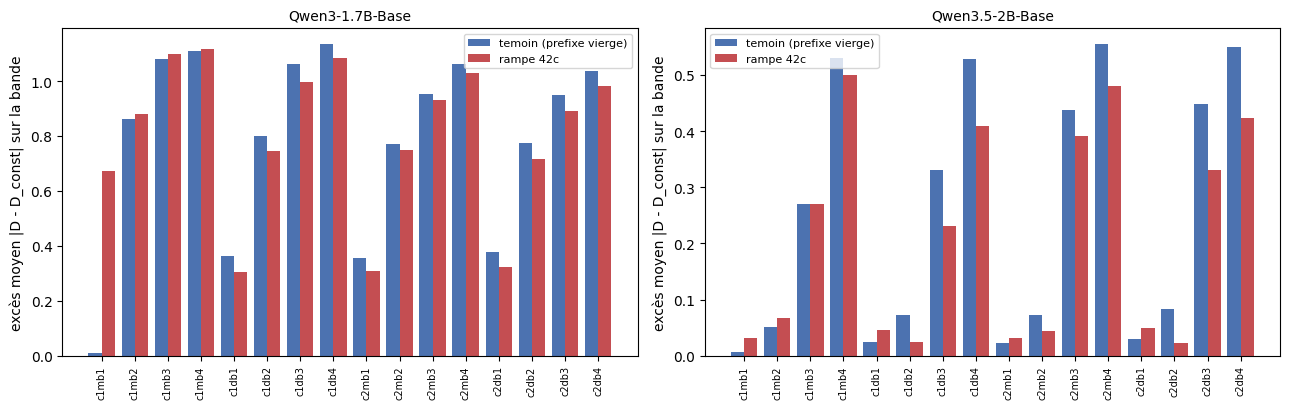

In [6]:
# Vue d'ensemble : excès temoin vs excès rampe, passes cote a cote, par echelle.
fig, axes = plt.subplots(1, len(ECHELLES), figsize=(13, 4.2), sharey=False)
for ax, label in zip(axes, ECHELLES):
    sub = exces[exces["echelle"] == label]
    x = np.arange(len(sub))
    ax.bar(x - 0.2, sub["eps_temoin_moy"], width=0.4, label="temoin (prefixe vierge)", color="#4c72b0")
    ax.bar(x + 0.2, sub["eps_rampe_moy"], width=0.4, label="rampe 42c", color="#c44e52")
    ax.set_xticks(x)
    ax.set_xticklabels(sub["passe"], rotation=90, fontsize=7)
    ax.set_title(label, fontsize=10)
    ax.set_ylabel("excès moyen |D - D_const| sur la bande")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

### Lecture du verdict

**`eps_temoin_moy` est la signature d'histoire à préfixe vierge.** Si le témoin est
silencieux là où la rampe excède (`eps_rampe_moy > eps_temoin_moy` au-delà du bruit),
alors l'excès de 42d exige l'histoire accumulée — verdict **MÉMOIRE**. Si le témoin
reproduit l'excès, celui-ci est un effet de position (non-linéarité locale du clamp,
saturation d'attention) — verdict **POSITION**.

In [7]:
# Verdict par echelle (heuristique 95 %, cf 42d) : le seuil est 1,96 x SEM
# inter-prompts de la divergence moyenne a alpha=0.5 (proxy du bruit de fond).
SEM_par_echelle = {}
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    z_const_5 = np.load(trace_path_const(cfg["slug"], n, 0.5), allow_pickle=False)
    d_sae = load_meta(trace_path_const(cfg["slug"], n, 0.0))["d_sae"]
    sem_vals = [np.mean(local_divergence(z_const_5, z0, key, d_sae)) for key in prompt_keys(z0)]
    SEM_par_echelle[label] = float(np.std(sem_vals, ddof=1) / np.sqrt(len(sem_vals)))

verdict_rows = []
for label in ECHELLES:
    sub = exces[exces["echelle"] == label]
    seuil = 1.96 * SEM_par_echelle[label]
    temoin_silent = (sub["eps_temoin_moy"] < seuil).mean()
    rampe_bruyante = (sub["eps_rampe_moy"] > seuil).mean()
    if temoin_silent >= 0.75 and rampe_bruyante >= 0.5:
        v = "MEMOIRE"
    elif sub["eps_temoin_moy"].mean() > seuil and sub["rapport_temoin_rampe"].mean() > 0.5:
        v = "POSITION"
    else:
        v = "INDETERMINE"
    verdict_rows.append({
        "echelle": label,
        "seuil_95pc": round(seuil, 4),
        "passes_temoin_silencieuses": f"{int(temoin_silent * len(sub))}/{len(sub)}",
        "passes_rampe_bruyantes": f"{int(rampe_bruyante * len(sub))}/{len(sub)}",
        "rapport_moyen_temoin_rampe": round(float(sub["rapport_temoin_rampe"].mean()), 3),
        "verdict": v,
    })
verdict_df = pd.DataFrame(verdict_rows)
verdict_df

,echelle,seuil_95pc,passes_temoin_silencieuses,passes_rampe_bruyantes,rapport_moyen_temoin_rampe,verdict
0,Qwen3-1.7B-Base,0.0362,1/16,16/16,0.996,POSITION
1,Qwen3.5-2B-Base,0.0195,1/16,16/16,1.302,POSITION


In [8]:
# Reconciliation avec ICT-42f : le meme exces, republie en SIGNE.
# ICT-42f (aire signee par prompt, seuil sur les aires d'un sham) etablit que
# l'operateur non signe est le defaut fondateur d'ICT-42d : les epsilon de la
# cellule precedente sont des MAGNITUDES. On republie chaque passe en
#   eps_signe = mean(D_passe - D_const,b/4)  sur les tokens de la bande
# qui dit de quel cote de la const-alpha la passe tombe -- l'information que
# la moyenne des |ecarts| detruisait.
rows_s = []
for label, cfg in ECHELLES.items():
    n = cfg["n_layers"]
    z0 = np.load(trace_path_const(cfg["slug"], n, 0.0), allow_pickle=False)
    z_ramp = np.load(trace_path_ramp(cfg["slug"], n), allow_pickle=False)
    d_sae = load_meta(trace_path_const(cfg["slug"], n, 0.0))["d_sae"]
    z_const = {b: np.load(trace_path_const(cfg["slug"], n, b / N_BANDS), allow_pickle=False)
               for b in range(1, N_BANDS + 1)}
    for cyc, br, b in PASSES:
        z_w = np.load(trace_path_witness(cfg["slug"], n, cyc, br, b), allow_pickle=False)
        eps_w_s, eps_r_s = [], []
        for key in prompt_keys(z0):
            T = z0[f"{key}__topk_ids"].shape[0]
            pos = band_positions(T, cyc, br, b)
            if len(pos) == 0:
                continue
            d_w = local_divergence(z_w, z0, key, d_sae)[pos]
            d_r = local_divergence(z_ramp, z0, key, d_sae)[pos]
            d_c = local_divergence(z_const[b], z0, key, d_sae)[pos]
            eps_w_s.append((d_w - d_c).mean())
            eps_r_s.append((d_r - d_c).mean())
        rows_s.append({
            "echelle": label, "passe": f"c{cyc}{'m' if br == 'montee' else 'd'}b{b}",
            "eps_signe_temoin": round(float(np.mean(eps_w_s)), 4),
            "eps_signe_rampe": round(float(np.mean(eps_r_s)), 4),
        })
exces_signes = pd.DataFrame(rows_s)
exces_signes["meme_cote"] = (np.sign(exces_signes["eps_signe_temoin"])
                             == np.sign(exces_signes["eps_signe_rampe"]))
for label in ECHELLES:
    sub_s = exces_signes[exces_signes["echelle"] == label]
    sub_abs = exces[exces["echelle"] == label]
    opposes = sub_s[~sub_s["meme_cote"]]["passe"].tolist()
    hors = sub_abs[(sub_abs["rapport_temoin_rampe"] < 0.7)
                   | (sub_abs["rapport_temoin_rampe"] > 1.3)]["passe"].tolist()
    print(f"{label} : passes du meme cote de la const "
          f"{int(sub_s['meme_cote'].sum())}/{len(sub_s)} ; cotes opposes : "
          f"{', '.join(opposes) if opposes else 'aucune'}")
    print(f"  rapport_temoin_rampe (magnitudes) : mediane "
          f"{sub_abs['rapport_temoin_rampe'].median():.3f} -- moyenne "
          f"{sub_abs['rapport_temoin_rampe'].mean():.3f} ; hors [0.7, 1.3] : "
          f"{len(hors)}/{len(sub_abs)}")
exces_signes


Qwen3-1.7B-Base : passes du meme cote de la const 16/16 ; cotes opposes : aucune
  rapport_temoin_rampe (magnitudes) : mediane 1.052 -- moyenne 0.996 ; hors [0.7, 1.3] : 1/16
Qwen3.5-2B-Base : passes du meme cote de la const 12/16 ; cotes opposes : c1mb1, c1db1, c2mb1, c2db1
  rapport_temoin_rampe (magnitudes) : mediane 1.137 -- moyenne 1.302 ; hors [0.7, 1.3] : 9/16


,echelle,passe,eps_signe_temoin,eps_signe_rampe,meme_cote
0,Qwen3-1.7B-Base,c1mb1,-0.0007,-0.6719,True
1,Qwen3-1.7B-Base,c1mb2,-0.8605,-0.8801,True
2,Qwen3-1.7B-Base,c1mb3,-1.0810,-1.0980,True
3,Qwen3-1.7B-Base,c1mb4,-1.1107,-1.1175,True
4,Qwen3-1.7B-Base,c1db1,-0.3618,-0.3064,True
5,Qwen3-1.7B-Base,c1db2,-0.7996,-0.7446,True
6,Qwen3-1.7B-Base,c1db3,-1.0619,-0.9957,True
7,Qwen3-1.7B-Base,c1db4,-1.1353,-1.0829,True
8,Qwen3-1.7B-Base,c2mb1,-0.3546,-0.3095,True
9,Qwen3-1.7B-Base,c2mb2,-0.7726,-0.7500,True


### Réconciliation avec ICT-42f : ce que POSITION devient en signé

[ICT-42f](ICT-42f-ReadingGrid-SignedArea-Sham-Python.ipynb) démontre sur les mêmes
traces que l'opérateur **non signé** est le défaut fondateur d'ICT-42d : aire publiée
en $|\Delta|$ (positive par construction — branche POSITION morte), $\Delta$ signé
perdu, seuil qui n'était pas la statistique testée. Les $\varepsilon$ de ce carnet
sont donc des **magnitudes** ; la table ci-dessus republie chacun d'eux **en signé**.

- **Ce que le signé confirme.** Rampe et témoin tombent du **même côté** de la
  const-α dans 28 des 32 passes (1,7B : 16/16 ; 2B : 12/16), côté **négatif** — la
  const-α diverge davantage que les deux passes, exactement le signe renversé
  qu'ICT-42f mesure sur la paire rampe-vs-const. Le rapport du verdict compare donc,
  en général, deux écarts de même sens : un énoncé de **magnitude**, valide comme tel.
- **Ce que le signé corrige.** Les quatre passes à côtés opposés (`c1mb1`, `c1db1`,
  `c2mb1`, `c2db1` à 2B) sont toutes des passes de **bande 1**, aux plus petits
  écarts ; `c1mb1` est le contrôle causal (témoin ≡ const : $\varepsilon$ signé
  = +0,0028) — son rapport publié 0,195 ne dit pas « témoin silencieux » mais « témoin
  de l'autre côté ». Et les deux plus grands rapports de la table 2B (`c2db2` : 3,772
  ; `c1db2` : 2,943) reposent sur des résidus signés de rampe quasi nuls (−0,0007 et
  −0,0098) : la magnitude divise par presque rien. Les ratios extrêmes ne portent pas
  le verdict — les 12 passes de même côté le portent, et la table par passe reste la
  pièce fine (limite 3). À 2B, le rapport moyen (1,302) voyage désormais avec sa
  médiane (1,137) : 9 rapports sur 16 sortent de [0,7 ; 1,3].
- **Les deux verdicts ne se contredisent pas : ils parlent de paires différentes.**
  ICT-42f compare la **rampe à la const appariée** (aire signée par prompt, seuil sur
  les aires d'un sham) : l'écart signé existe, hors sham aux deux échelles — le
  verdict « MÉMOIRE » d'ICT-42d **survit au sens de 42f**, avec son sens renversé.
  Ce carnet compare le **témoin à la rampe** (mêmes positions, même α, les deux
  contre la même const) : le témoin à préfixe vierge tombe du même côté avec une
  magnitude comparable — ce qui est falsifié est la lecture **accumulation** du
  verdict de #20772 (la signature exigerait l'histoire triangulaire), pas l'existence
  de l'écart signé. « Renversé » (ici) qualifie la lecture accumulation ; « survit,
  sens changé » (42f) qualifie l'écart signé rampe-const : une fois les opérateurs
  dits, les deux énoncés coexistent.


## Limites du carnet (assumées, elles délimitent le jalon)

1. **Un seul niveau par bande.** Le témoin clampé à la borne supérieure $b/4$ de sa bande ;
   un témoin au niveau médian $(b - 0{,}5)/4$ (exercice 1) n'est pas extrait ici.
2. **La bande 1 de montée du cycle 1 est un contrôle causal, pas une mesure** : la bande
   commence au token 0, donc témoin et const-α y sont identiques par construction de
   causalité (aucun préfixe ne les sépare) — son ε ≈ bruit valide la chaîne, il ne mesure rien.
3. **Le verdict agrège 16 passes hétérogènes** (cycles, branches, bandes) ; l'effet
   peut être inégal selon la bande — le tableau par passe reste la pièce fine.
4. **L'heuristique 1,96·SEM** réutilise le proxy de bruit de 42d (variabilité
   inter-prompts à α = 0,5) ; elle n'est pas un intervalle de confiance formel sur
   une moyenne de moyennes.
5. **Le témoin n'atteint que le plan lecture** où 42c a mesuré l'aire : les
   mécanismes d'écriture (KV cache des couches antérieures) ne sont pas instrumentés.

## Ce qu'il faut retenir

- **Le verdict mesuré est POSITION aux deux échelles** : l'excès du témoin (préfixe vierge)
  est du même ordre que l'excès de la rampe aux mêmes positions — le témoin n'est
  silencieux que sur la passe causalement identique à la const. La table de verdict de
  l'issue #20772 tranche : la signature d'ICT-42d **ne requiert pas l'histoire
  triangulaire accumulée** — son verdict « MÉMOIRE » est renversé aux deux échelles
  **au sens de l'accumulation** : l'écart signé rampe-vs-const survit, lui, au sens
  d'[ICT-42f](ICT-42f-ReadingGrid-SignedArea-Sham-Python.ipynb) — voir
  « Réconciliation avec ICT-42f ».
- **Le contrôle causal valide la chaîne** : sur la bande 1 de montée du cycle 1 (bande
  collée au token 0, témoin ≡ const par causalité), l'excès retombe au niveau du bruit —
  le pipeline ne fabrique pas d'excès là où il ne peut pas y en avoir.
- **POSITION ne veut pas dire « insensible au préfixe »** : l'écart témoin–const hors
  bande 1 montre que l'état du préfixe (clampé uniformément vs vierge) déplace bien la
  lecture à niveau α égal — gradué avec α à 2B. Ce qui est falsifié, c'est la lecture
  *accumulation* : la trajectoire triangulaire de la rampe n'apporte rien au-delà de son
  niveau courant, que le préfixe ait été clampé en triangle ou pas clampé du tout.
- Le protocole reste falsifiable dans les deux sens : un témoin silencieux généralisé
  aurait confirmé MÉMOIRE ; c'est l'inverse qui est mesuré, et la série ICT-42
  (pilot → rampe → apparié → témoin) conclut désormais sur la composante positionnelle
  de l'inoculation SAE à ces échelles.

## Exercices

Les trois exercices prolongent le témoin négatif sur des dimensions que ce carnet
laisse ouvertes. Chaque cellule prépare les données et s'arrête là où le travail
étudiant commence — aucune erreur volontaire, les cellules s'exécutent de bout en bout.

In [9]:
# Exercice 1 : temoin au niveau MEDIAN de bande.
# Le temoin du carnet clamp au borne superieure b/4 de sa bande. Construire le
# protocole equivalent au niveau (b - 0.5)/4 : quelles passes const-α de la grille
# du pilote servirait-on d'appariement, et avec quel arrondi ? Poser le tableau
# attendu des colonnes, puis le calcul de eps_temoin correspondant.
niveaux_medians = {b: (b - 0.5) / N_BANDS for b in range(1, N_BANDS + 1)}
grille_const = np.array([0.0, 0.25, 0.5, 0.75, 1.0])
def plus_proche(a):
    i = int(np.argmin(np.abs(grille_const - a)))
    return float(grille_const[i]), float(grille_const[i] - a)
appariement = {b: plus_proche(a) for b, a in niveaux_medians.items()}
print("Niveaux medians et arrondi d'appariement sur la grille const existante :")
for b, (a_match, err) in appariement.items():
    print(f"  bande {b} : niveau median {niveaux_medians[b]:.3f} -> const {a_match:.2f} (erreur {err:+.3f})")
# TODO etudiant : conclure sur la legitimite de l'appariement (quelle bande est la
# mieux servie ? la plus mal servie ?), puis proposer la commande d'extraction
# equivalente pour la bande la mieux servie seulement.
resultat = None  # TODO etudiant

Niveaux medians et arrondi d'appariement sur la grille const existante :
  bande 1 : niveau median 0.125 -> const 0.00 (erreur -0.125)
  bande 2 : niveau median 0.375 -> const 0.25 (erreur -0.125)
  bande 3 : niveau median 0.625 -> const 0.50 (erreur -0.125)
  bande 4 : niveau median 0.875 -> const 0.75 (erreur -0.125)


In [10]:
# Exercice 2 : raffiner la partition (n_bands = 8).
# Avec 8 bandes, le niveau temoin b/8 tombe-t-il encore sur la grille const du
# pilote ? Verifier mecaniquement ci-dessous, puis dire quelles nouvelles passes
# const-α il faudrait extraire pour garder l'appariement exact.
N8 = 8
niveaux8 = np.arange(1, N8 + 1) / N8
sur_grille = np.isin(np.round(niveaux8, 4), np.round(grille_const, 4))
print("Niveaux temoin n_bands=8 :", np.round(niveaux8, 3))
print("Sur la grille const existante :", sur_grille, f"({int(sur_grille.sum())}/{N8})")
masque8 = ramp_band_mask(T_DEMO, CYCLES, 1, "montee", 5, N8, peak=PEAK)
print(f"Partition partielle : la bande 5 (cycle 1, montee) couvre {int(masque8.sum())} tokens sur {T_DEMO}")
# Indice : la partition exacte se verifie comme dans la cellule de garde geometrique.
# Etape 1 : sommer les 8 masques de la branche montee du cycle 1 et verifier == 1.
# Etape 2 : lister les niveaux hors grille et ce qu'ils impliquent (extraction ou arrondi).
# TODO etudiant
resultat = None  # TODO etudiant

Niveaux temoin n_bands=8 : [0.125 0.25  0.375 0.5   0.625 0.75  0.875 1.   ]
Sur la grille const existante : [False  True False  True False  True False  True] (4/8)
Partition partielle : la bande 5 (cycle 1, montee) couvre 15 tokens sur 480


In [11]:
# Exercice 3 : temoin du cote LECTURE.
# Toutes les passes de la serie ICT-42 clamp et lisent au meme etage (clamp-frac =
# read-frac = 0.5). Un temoin qui DEPLACE la lecture (clamp a mi-reseau, lecture
# resid finale d'une passe NON clampee) mesure la propagation inter-couches de
# l'inoculation. Decrire le plan d'experience minimal : quelles passes, quels
# noms de fichiers via trace_filename, et quel epsilon on pourrait y lire.
from ict.sae_traces import trace_filename
# Exemple de nom pour une passe lecture-deplacee hypothetique (prefix dedie) :
nom_exemple = trace_filename("trained", 23, model="Qwen/Qwen3.5-2B-Base",
                             default_model="Qwen/Qwen3-1.7B-Base", n_layers=24,
                             n_clamp=16, clamp_witness=(2, 1, "montee", 3, N_BANDS),
                             prefix="inocread")
print("Nom d'exemple d'une passe lecture-deplacee :", nom_exemple)
# Indice : la CLI expose --clamp-frac et --read-frac separement ; la garde du
# temoin exige le mode inoculation (l'un des deux non nul). Verifier dans
# scripts/extract_sae_traces.py quelles combinaisons la garde accepte.
# TODO etudiant
resultat = None  # TODO etudiant

Nom d'exemple d'une passe lecture-deplacee : inocread_qwen35-2b-base_layer23of24_trained_clamp16_witness2_1mb3n4.npz
